# Games (Adversarial Search)

**Agenda**

1. Games: games vs search problems, perfect and complete information, types of games
2. Minimax: MAX and MIN, the game tree, backing up values, tic-tac-toe, properties, conditions for optimality
3. Alpha-beta pruning: α, β and the window [α, β], working example, properties, move ordering
4. Resource limits: cutting off the search, evaluation functions
5. Summary
6. Homework: Tic-Tac-Toe

## Setup: imports and helper code

The helpers draw game trees (with the values, α and β of every node, and the pruned branches marked with ✂) and
tic-tac-toe boards. `trace_search` runs minimax or alpha-beta on a tree and remembers everything the drawing needs.
You do not need to understand the drawing code.

In [1]:
# The imports used in the rest of the notebook
import math

import matplotlib.pyplot as plt

In [2]:
# Helper code that can be skipped

def show_number(value):
    # -inf -> "−∞", 3.0 -> "3"
    if value in (math.inf, -math.inf):
        return "+∞" if value > 0 else "−∞"
    return f"{value:g}".replace("-", "−")


def tree_nodes(tree, path=()):
    # every node of a nested-list tree, as {path: node}; the path of a node is the list of child indices to reach it
    nodes = {path: tree}
    if isinstance(tree, list):
        for i, child in enumerate(tree):
            nodes.update(tree_nodes(child, path + (i,)))
    return nodes


def trace_search(tree, root_is_max=True, prune=True):
    # minimax (prune=False) or alpha-beta (prune=True) on a nested-list tree, remembering every node's value,
    # its final alpha and beta, the pruned children and the evaluated leaves
    values, notes, pruned, evaluated = {}, {}, set(), []

    def search(node, path, alpha, beta, maximizing):
        if not isinstance(node, list):
            evaluated.append(path)
            return node
        best = -math.inf if maximizing else math.inf
        for i, child in enumerate(node):
            value = search(child, path + (i,), alpha, beta, not maximizing)
            if maximizing:
                best = max(best, value)
                alpha = max(alpha, best)
            else:
                best = min(best, value)
                beta = min(beta, best)
            if prune and beta <= alpha:
                pruned.update(path + (j,) for j in range(i + 1, len(node)))
                break
        values[path] = best
        notes[path] = f"α={show_number(alpha)}, β={show_number(beta)}"
        return best

    search(tree, (), -math.inf, math.inf, root_is_max)
    return values, notes, pruned, evaluated


def draw_game_tree(tree, title="", root_is_max=True, values=None, notes=None, pruned=(), highlight=(),
                   node_types=None, edge_labels=None, figsize=(10, 4.2)):
    # ▲ = MAX, ▼ = MIN, ● = chance, ■ = leaf; dashed grey = never looked at; ✂ = pruned edge
    values, notes = values or {}, notes or {}
    node_types, edge_labels = node_types or {}, edge_labels or {}
    nodes = tree_nodes(tree)
    leaves = [p for p, n in nodes.items() if not isinstance(n, list)]
    x = {p: i for i, p in enumerate(leaves)}
    for p in sorted(nodes, key=len, reverse=True):                 # a parent sits above the middle of its children
        if p not in x:
            x[p] = sum(x[p + (i,)] for i in range(len(nodes[p]))) / len(nodes[p])

    def kind(p):
        if p in node_types:
            return node_types[p]
        if not isinstance(nodes[p], list):
            return "leaf"
        return "max" if (len(p) % 2 == 0) == root_is_max else "min"

    def skipped(p):
        return any(p[:k] in pruned for k in range(1, len(p) + 1))

    fig, ax = plt.subplots(figsize=figsize)
    for p in nodes:
        if p == ():
            continue
        parent = p[:-1]
        colour = "#2e7d32" if p in highlight else "#cccccc" if skipped(p) else "#555555"
        ax.plot([x[parent], x[p]], [-len(parent), -len(p)], color=colour, lw=3 if p in highlight else 1.5,
                linestyle="--" if skipped(p) else "-", zorder=1)
        at = 0.4                                                     # 40% of the way from the parent
        mx, my = x[parent] + at * (x[p] - x[parent]), -len(parent) - at
        if p in pruned:
            ax.text(mx, my, "✂", color="#c62828", fontsize=15, ha="center", va="center", zorder=3)
        if p in edge_labels:
            ax.text(mx - 0.1, my, edge_labels[p], fontsize=10, ha="right", va="center")
    for p in nodes:
        k = kind(p)
        marker, fill = {"max": ("^", "white"), "min": ("v", "#9ecae1"), "chance": ("o", "#e0e0e0"),
                        "leaf": ("s", "#fff3c4")}[k]
        faded = skipped(p)
        ax.scatter([x[p]], [-len(p)], marker=marker, s=950 if k != "leaf" else 650, c=fill, linewidths=1.5,
                   edgecolors="#cccccc" if faded else "black", zorder=2)
        label = show_number(nodes[p]) if k == "leaf" else show_number(values[p]) if p in values else ""
        offset = {"max": -0.06, "min": 0.06}.get(k, 0)
        ax.text(x[p], -len(p) + offset, label, ha="center", va="center", fontsize=10, fontweight="bold",
                color="#bbbbbb" if faded else "black", zorder=3)
        if p in notes and not faded:
            ax.text(x[p] + 0.3, -len(p) + 0.22, notes[p], ha="left", va="center", fontsize=8, color="#1f4e79",
                    zorder=4, bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 1})
    depth = max(len(p) for p in nodes)
    for d in range(depth + 1):
        kinds = {kind(p) for p in nodes if len(p) == d} - {"leaf"}
        ax.text(-0.8, -d, kinds.pop().upper() if kinds else "LEAVES", ha="right", va="center", fontsize=10,
                fontweight="bold")
    ax.set_xlim(-2.1, len(leaves) + 0.3)
    ax.set_ylim(-depth - 0.6, 0.6)
    ax.axis("off")
    ax.set_title(title)
    plt.close(fig)
    return fig


def draw_board(ax, board, x, y, size=0.8, last_move=None):
    # a small tic-tac-toe board centred at (x, y); the last move is red
    cell = size / 3
    left, top = x - size / 2, y + size / 2
    ax.add_patch(plt.Rectangle((left, top - size), size, size, facecolor="white", edgecolor="black", zorder=2))
    for k in (1, 2):
        ax.plot([left + k * cell] * 2, [top - size, top], color="black", lw=0.8, zorder=3)
        ax.plot([left, left + size], [top - k * cell] * 2, color="black", lw=0.8, zorder=3)
    for index, mark in enumerate(board):
        if mark != " ":
            row, col = divmod(index, 3)
            colour = "#c62828" if index == last_move else "#1f4e79" if mark == "X" else "#333333"
            ax.text(left + (col + 0.5) * cell, top - (row + 0.5) * cell, mark, ha="center", va="center",
                    fontsize=9, fontweight="bold", color=colour, zorder=4)


def draw_tic_tac_toe_tree(game, board, maximizing, title=""):
    # the whole game tree below `board` with the minimax value of every board; green = the best moves
    nodes = {}

    def build(state, path, maximizing, last_move):
        nodes[path] = (state, maximizing, last_move)
        if not game.is_terminal(state):
            for i, (move, child) in enumerate(game.children(state, maximizing)):
                build(child, path + (i,), not maximizing, move)

    build(board, (), maximizing, None)
    kids = {p: [q for q in nodes if len(q) == len(p) + 1 and q[:-1] == p] for p in nodes}
    values, x = {}, {}
    leaves = [p for p in sorted(nodes) if not kids[p]]
    for p in sorted(nodes, key=len, reverse=True):
        state, is_max, _ = nodes[p]
        if kids[p]:
            values[p] = (max if is_max else min)(values[q] for q in kids[p])
            x[p] = sum(x[q] for q in kids[p]) / len(kids[p])
        else:
            values[p] = game.evaluate(state)
            x[p] = 1.2 * leaves.index(p)

    fig, ax = plt.subplots(figsize=(1.1 * len(leaves) + 2, 6.5))
    for p, (state, is_max, last_move) in nodes.items():
        if p:
            parent_max = nodes[p[:-1]][1]
            best = values[p] == (max if parent_max else min)(values[q] for q in kids[p[:-1]])
            ax.plot([x[p[:-1]], x[p]], [-1.6 * (len(p) - 1), -1.6 * len(p)], zorder=1,
                    color="#2e7d32" if best else "#aaaaaa", lw=2.5 if best else 1)
        draw_board(ax, state, x[p], -1.6 * len(p), last_move=last_move)
        ax.text(x[p] + 0.47, -1.6 * len(p), f"{values[p]:+d}" if values[p] else "0", ha="left", va="center",
                fontsize=10, fontweight="bold")
    for d in range(max(len(p) for p in nodes) + 1):
        level = {nodes[p][1] for p in nodes if len(p) == d}
        ax.text(-1.0, -1.6 * d, "MAX (X)" if level == {True} else "MIN (O)", ha="right", va="center",
                fontsize=10, fontweight="bold")
    ax.set_xlim(-2.6, max(x.values()) + 1.0)
    ax.set_ylim(-1.6 * max(len(p) for p in nodes) - 0.8, 0.8)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title)
    plt.close(fig)
    return fig

---

# 1. Games

## 1.1 Games vs search problems

In the search problems so far we controlled every move. In a game there is an **opponent**:

- **"Unpredictable" opponent**: the solution is not a fixed sequence of moves, but a **strategy** - a move for every possible reply of the opponent.
- **Time limits**: we are unlikely to find the goal (the end of the game) when searching during our turn, because states are too many. This means we must **approximate**.

## 1.2 Perfect and complete information

- **Perfect information**: every player knows every move that has ever been made by all players up to the current point in the game, also including the current game state. This means there is no hidden history.
- **Complete information** (knowledge of **rules and payoffs**): every player knows the rules, the possible actions and the payoff of every player - **no hidden incentives**. The end goal of every player is known to every other player.
-  **Deterministic**: The next state depends only on the current state and the move chosen, not on random outcomes.

|  | Deterministic | Chance |
|---|---|---|
| **Perfect information** | chess, checkers, go, othello | backgammon, monopoly |
| **Complete, but imperfect information** | battleships, kriegspiel, stratego | bridge, poker, scrabble |


**Is it true that if a game has perfect information, it also has complete information? No!** A counterexample - a
sequential bargaining game: Player 1 sells an item and makes a proposal for the price, and Player 2 accepts or rejects it.

- **Perfect information? Yes.** Player 2 sees Player 1's price, and if Player 2 rejects, Player 1 sees the rejection. All moves are transparent.
- **Complete information? Maybe not.** Player 1 might not know the maximum amount Player 2 is willing to accept. That threshold is private, hidden information.

## 1.3 Types of games

Game theory sorts games along many more dimensions:

| Type | Meaning |
|---|---|
| **Cooperative / non-cooperative** | can the players make binding agreements and act as a coalition? |
| **Symmetric / asymmetric** | do the payoffs depend only on the strategies, not on who plays them? |
| **Zero-sum / non-zero-sum** | is one player's gain exactly the other's loss, or can both win (or lose)? |
| **Simultaneous / sequential** | do the players move at the same time (rock-paper-scissors) or in turns (chess)? |
| **Perfect / imperfect information** | does every player see all previous moves? |
| **Combinatorial games** | two players, sequential, perfect information, no chance - e.g. chess, go, nim |
| **Infinitely long games** | games that can go on forever; studied in set theory |
| **Discrete / continuous games** | a finite number of choices, or a continuum (e.g. choosing a price) |
| **Differential games** | the state changes continuously in time by differential equations (e.g. pursuit and evasion) |
| **Evolutionary game theory** | populations of strategies; successful strategies multiply, like in natural selection |
| **Stochastic outcomes** | chance plays a role (dice, cards); related to decision theory |
| **Metagames** | games whose outcome is the rules of another game (e.g. designing an auction) |
| **Pooling games** | repeated games whose payoff table changes over time; their equilibria become social and economic conventions |
| **Mean field game theory** | a very large number of small players, each reacting to the average behaviour of all others |

In this seminar we will be looking at **two players, zero-sum, sequential (turn taking), deterministic and perfect information** games.

---

# 2. Minimax

## 2.1 MAX and MIN

Minimax is perfect play for deterministic, perfect-information games. Its core principle is to **minimize the maximum
possible loss** for the current player, assuming that the opponent always plays optimally.

- **MAX** (player 1) tries to **maximize** the score.
- **MIN** (player 2) tries to **minimize** the score.

There is **one** score, a high number is good for MAX, a low number
is good for MIN. In a **zero-sum** game, whatever MAX wins, MIN loses - so making MAX's score as low as possible is the
same as making MIN's own score as high as possible.

## 2.2 The game tree

A game tree is a directed graph where:

- **nodes** are possible states of the game (e.g. board configurations)
- **edges** are moves from one game state to the next
- the **root** is the current position
- the **levels alternate** between MAX and MIN, because the players take turns
- the **leaves** are finished games (terminal states); they get a score from the **utility** (evaluation) function

For tic-tac-toe: **X wins → +1**, **O wins → −1**, **draw → 0**. So X is MAX and O is MIN. From the empty board there
are 9 moves for X, then 8 for O, and so on - the full tree has 255,168 finished games.


## 2.3 Backing up the values

Below is the tree we use for the rest of the lecture: MAX at the root, then MIN, then MAX, then the leaves. We know the
leaves. Every inner value is computed from its children, **bottom up**: a MAX node takes the **maximum** from its children, a MIN node
the **minimum** from its children:

- MAX level: max(−1, 3) = **3**, max(5, 1) = **5**, max(−6, −4) = **−4**, max(0, 9) = **9**
- MIN level: min(3, 5) = **3**, min(−4, 9) = **−4**
- root (MAX): max(3, −4) = **3**

The root value is **3**: if both players play optimally, MAX gets 3. MAX should go **left** (the green path is the game
that will be played).

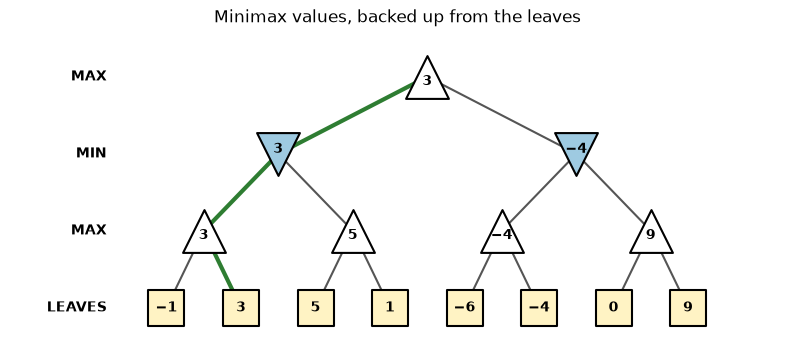

In [3]:
game_tree = [
    [
        [-1, 3],
        [5, 1],
    ],
    [
        [-6, -4],
        [0, 9],
    ],
]

_values, _, _, _ = trace_search(game_tree, prune=False)
draw_game_tree(game_tree, values=_values, highlight={(0,), (0, 0), (0, 0, 1)},
               title="Minimax values, backed up from the leaves")

## 2.4 The minimax algorithm

Minimax works for any game, as long as we can answer three questions:

- `is_terminal(state)`: is the game over?
- `evaluate(state)`: the score of a finished position (the utility)
- `children(state, maximizing)`: the positions reachable in one move, as `(move, new state)` pairs

So a game is a class with these three methods. The simplest game is a tree written as **nested lists**: a list is an
inner node, a number is a leaf, and the "moves" are the indices of the children.

In [4]:
class TreeGame:
    # a game tree written as nested lists: a list is an inner node, a number is a leaf
    def is_terminal(self, node):
        return not isinstance(node, list)

    def evaluate(self, node):
        return node

    def children(self, node, maximizing):
        return list(enumerate(node))                   # (index of the child, child)


def minimax(game, state, maximizing):
    if game.is_terminal(state):
        return game.evaluate(state)

    if maximizing:
        best = -math.inf
        for move, child in game.children(state, True):
            best = max(best, minimax(game, child, False))
        return best
    else:
        best = math.inf
        for move, child in game.children(state, False):
            best = min(best, minimax(game, child, True))
        return best


def best_move(game, state, maximizing, search=minimax):
    # the value of every legal move, and the best move for the player to move
    scores = {move: search(game, child, not maximizing) for move, child in game.children(state, maximizing)}
    pick = max if maximizing else min
    return pick(scores, key=scores.get), scores


print("minimax value of the root:", minimax(TreeGame(), game_tree, True))
print("(best move, value of each move):", best_move(TreeGame(), game_tree, True))

minimax value of the root: 3
(best move, value of each move): (0, {0: 3, 1: -4})


`best_move` returns move `0` (left) with value 3; the right move is worth only −4.

## 2.5 A real game: tic-tac-toe

Now the same `minimax` on real boards. A board is a list of 9 cells, numbered row by row; each cell is `"X"`, `"O"` or
`" "` (empty):

```
 0 | 1 | 2
---+---+---
 3 | 4 | 5
---+---+---
 6 | 7 | 8
```

By default X is MAX and O is MIN, and the utility is the one from above (+1 / −1 / 0). The class takes an argument `max_mark` that tells us which mark is MAX.

In [5]:
LINES = [(0, 1, 2), (3, 4, 5), (6, 7, 8),   # rows
         (0, 3, 6), (1, 4, 7), (2, 5, 8),   # columns
         (0, 4, 8), (2, 4, 6)]              # diagonals


class TicTacToe:
    def __init__(self, max_mark="X"):
        self.max_mark = max_mark
        self.min_mark = "O" if max_mark == "X" else "X"

    def winner(self, board):
        for a, b, c in LINES:
            if board[a] != " " and board[a] == board[b] == board[c]:
                return board[a]
        return None

    def is_terminal(self, board):
        return self.winner(board) is not None or " " not in board

    def evaluate(self, board):
        winner = self.winner(board)
        if winner is None:
            return 0
        return 1 if winner == self.max_mark else -1

    def children(self, board, maximizing):
        mark = self.max_mark if maximizing else self.min_mark
        return [(cell, board[:cell] + [mark] + board[cell + 1:]) for cell in range(9) if board[cell] == " "]

O (MIN) is to move and has three free cells: 4, 6 and 8. The whole game tree
below it is small enough to draw - the number next to each board is its minimax value, and the red mark is the move
that led to it:

minimax value of each move for O: {4: -1, 6: 1, 8: 1}
O plays cell 4


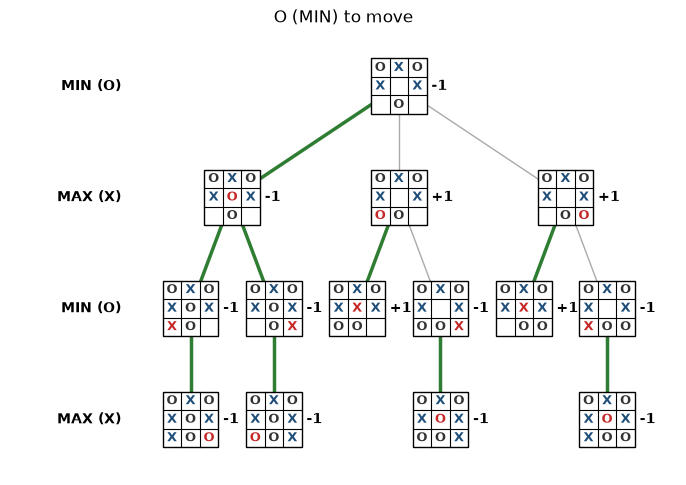

In [6]:
lecture_position = ["O", "X", "O",
                    "X", " ", "X",
                    " ", "O", " "]

_move, _scores = best_move(TicTacToe(), lecture_position, maximizing=False)   # O = MIN is to move
print("minimax value of each move for O:", _scores)
print("O plays cell", _move)

draw_tic_tac_toe_tree(TicTacToe(), lecture_position, maximizing=False, title="O (MIN) to move")

## 2.6 Properties of minimax

| Property | Minimax |
|---|---|
| **Complete?** | **Yes**, if the tree is finite |
| **Optimal?** | **Yes**, against an optimal opponent |
| **Time complexity** | $O(b^m)$ |
| **Space complexity** | $O(bm)$ (depth-first exploration) |

$b$ = the number of legal moves in a position (branching factor), $m$ = the maximum depth of the tree.

- **Complete**: chess has specific rules to keep the tree finite (a draw by threefold repetition, the fifty-move
  rule).
- **Optimal (picks the move with the best worst-case outcome)**: Minimax never does worse than its minimax value - but it assumes
  the opponent is perfect, so it may miss a chance to win faster or with better score against an opponent who makes mistakes.
- **Space**: minimax is a depth-first search - it only keeps the current path, and the siblings on it.

Tic-tac-toe is small: we just searched all 549,946 positions in about a second. Chess has $b \approx 35$ and
$m \approx 100$ for "reasonable" games, so $35^{100} \approx 10^{154}$ positions - an exact solution is completely
infeasible. **But we do not need to explore every path, as we will see later.**

## 2.7 Conditions for minimax optimality

Minimax guarantees the optimal move *for the worst-case scenario* against a rational opponent, provided that:

- **Two players**: the max / min structure breaks down with more players.
- **Zero-sum**: the gain of one player is exactly the loss of the other, so MAX's goal (maximize my score) is exactly
  the inverse of MIN's goal.
- **Perfect information**: both players know the entire state of the game (chess, checkers, tic-tac-toe). With
  hidden information (poker), minimax is no longer guaranteed to be optimal.
- **Deterministic**: no element of chance (no dice, no shuffled cards). With chance, a variant called
  **expectiminimax** is used.
- **Complete search**: the search must reach the terminal (game-ending) states. In real games like chess this is
  impossible, since there are way too many states. In this case, the search can stop at a fixed depth (the **search horizon**) and use a heuristic evaluation function for
  the non-terminal positions. The result will be only heuristically optimal, which is an approximation.

Minimax is typically used in classical games like chess, checkers and tic-tac-toe.

---

# 3. Alpha-beta pruning

## 3.1 Do we need to evaluate the whole game tree?

Look at the tree from the previous example again, this time going from left to right as the search does:

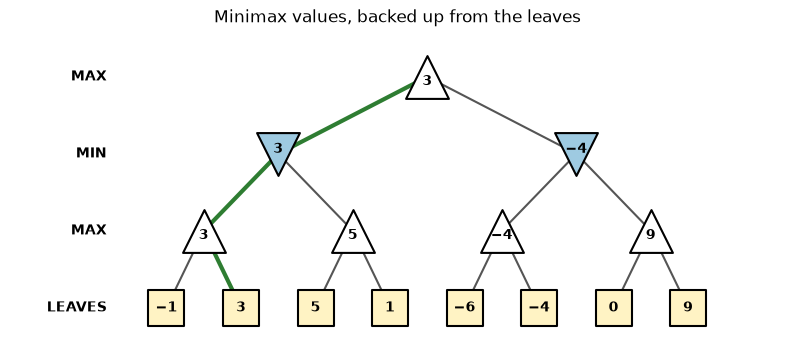

In [7]:
_values, _, _, _ = trace_search(game_tree, prune=False)
draw_game_tree(game_tree, values=_values, highlight={(0,), (0, 0), (0, 0, 1)},
               title="Minimax values, backed up from the leaves")

- The left MIN node has a child worth **3**. Its right MAX child is **>= 5**, because the first leaf is 5, and since it is a MAX
  node, it can only go up. This means that MIN will never choose it, since it already has 3 ensured by going left, so the last leaf with a value of 1 **does not matter**.
- At the root, MAX can get **3** on the left. On the right, MIN can ensure **≤ −4** after the first MAX child, which is worse for the MAX at root than the 3 it already has. This means that MAX will never go right, so the **whole second subtree of MIN** (leaves 0
  and 9) does not matter.

Only 5 of the 8 leaves are needed to get the correct root value 3. Which leaves can be skipped depends on the order in
which the moves are explored.

## 3.2 From the example to α and β

In the example we pruned twice, and each time we compared the node with something we had already found earlier in the tree:

1. Under the left MIN node: "MIN can already get **3** here." Any MAX child worth more than 3 is useless for MIN. This
   number is a bound that **MIN** guarantees. We call it **β**.
2. Under the root: "MAX can already get **3** on the left." Any MIN child worth less than 3 is useless for MAX. This
   number is a bound that **MAX** guarantees. We call it **α**.

To do this in general, every node carries two numbers down to its children:

- **α (alpha)**: the value of the best alternative for **MAX** found so far along the path to this node. It starts at
  **−∞**.
- **β (beta)**: the value of the best alternative for **MIN** found so far along the path to this node. It starts at
  **+∞**.

Update rules:

- A **MAX** node raises α: after each child, `alpha = max(alpha, value)`.
- A **MIN** node lowers β: after each child, `beta = min(beta, value)`.
- A node passes its current α and β **down** to the next child. What goes back **up** is the node's value, not α or β.

**Why is it called α-β?** α is the best value (for MAX) found so far off the current path. If a node V is worse than α,
MAX will avoid it ⇒ prune that branch. β is defined similarly for MIN.

## 3.3 The window [α, β]

Read α and β together as an interval **[α, β]** - an **allow list** of values. Only a value inside the window can still
change the move chosen at the root:

- A value **≤ α** is too low: MAX will not let the game get here, it already has α somewhere else.
- A value **≥ β** is too high: MIN will not let the game get here, it already has β somewhere else.

While we search, MAX nodes push α up (the left end moves right) and MIN nodes push β down (the right end moves left).
Going deeper, the window can only get smaller. **When the window becomes empty, we prune**: no value from the remaining
children can be accepted by both players, so there is no reason to look at them.

$$\text{prune when } \beta \le \alpha$$

- At a **MAX** node: MIN had a better option available earlier in the tree, so MIN will never let the game reach this
  node.
- At a **MIN** node: MAX had a better option available earlier in the tree, so MAX will never let the game reach this
  node.

In both cases: stop looking at the remaining children of this node.

The edge case $\alpha = \beta$: the window holds a single value, the one we already have. A child can at best tie with
it, so it cannot change the decision either. That is why we prune already at $\beta = \alpha$.

## 3.4 Working example

The same tree. Next to each node: its value and its α and β when it is finished; ✂ marks the pruned branches:

leaves evaluated: 5 of 8


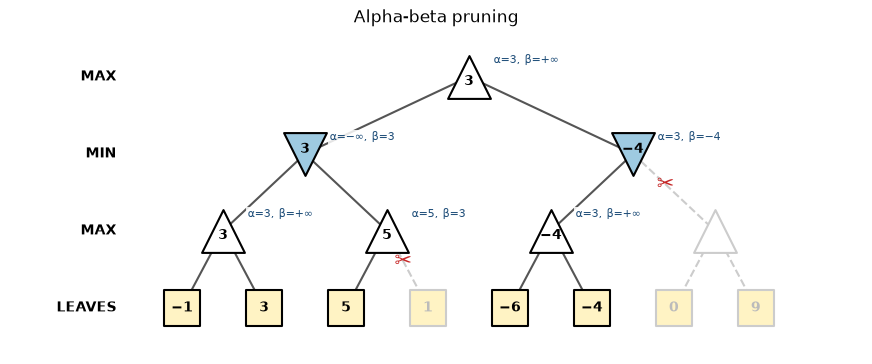

In [8]:
_values, _notes, _pruned, _evaluated = trace_search(game_tree)
print(f"leaves evaluated: {len(_evaluated)} of 8")
draw_game_tree(game_tree, values=_values, notes=_notes, pruned=_pruned, figsize=(11, 4.2),
               title="Alpha-beta pruning")

**IMPORTANT: When going down, we pass the whole current interval to the child. When going up we only pass the value to the parent, not the whole interval. If at any point β ≤ α, we prune.**

What happens, step by step:

1. Root starts with [−∞, +∞]
2. Root passes [−∞, +∞] to the first MIN
3. The first MIN passes [−∞, +∞] to the first MAX
4. The first leaf is -1, and this updates the first MAX's interval to [-1, +∞]
5. The second leaf is 3, and this updates the first MAX's interval to [3, +∞]
6. The first MAX's value is passed up to the first MIN
7. The first MIN updates its interval to [−∞, 3] (note that only the first MAX's value is passed up, not the whole MAX's interval) - since this is a MIN node, we update β.
8. The first MIN passes [−∞, 3] to the second MAX
9. The third leaf is 5, and this updates the second MAX's interval to [5, 3] - **this means β ≤ α and we prune**
10. The second MAX's value (which is 5) is passed up to the first MIN, but this doesn't update the first MIN's interval, since MIN's current β is 3, which is less than the passed 5.
11. The first MIN's value (which is 3) is passed up to the root
12. Root updates its interval to [3, +∞]
13. Root passes [3, +∞] to the second MIN
14. The second MIN passes [3, +∞] to the third MAX
15. Both leaves -6 and -4 are less than the third MAX's α = 3, so the interval for the third MAX is not updated.
16. The third MAX's value (which is -4) is passed to the second MIN
17. The second MIN updates its interval to [3, -4] - **this means β ≤ α and we prune**
18. The second MIN's value (which is -4) is passed up to the root: root = max(3, -4) = **3**, so MAX goes left - the same result as minimax, with only 5 of the 8 leaves evaluated

## 3.5 The α-β algorithm

In [9]:
def alpha_beta(game, state, alpha, beta, maximizing):
    if game.is_terminal(state):
        return game.evaluate(state)

    if maximizing:
        best = -math.inf
        for move, child in game.children(state, True):
            best = max(best, alpha_beta(game, child, alpha, beta, False))
            alpha = max(alpha, best)
            if beta <= alpha:
                break
        return best
    else:
        best = math.inf
        for move, child in game.children(state, False):
            best = min(best, alpha_beta(game, child, alpha, beta, True))
            beta = min(beta, best)
            if beta <= alpha:
                break
        return best


print("alpha-beta value of the root:", alpha_beta(TreeGame(), game_tree, -math.inf, math.inf, True))

alpha-beta value of the root: 3


## 3.6 Properties of alpha-beta pruning

- **Pruning does not affect the final result.** Alpha-beta returns the same root value (and the same best move) as
  minimax. It only skips work that cannot change the decision.
- **Good move ordering improves the effectiveness of pruning.** If the best moves are tried first, the window shrinks
  fast and more branches get cut.
- With **perfect ordering**, alpha-beta drops time complexity from $O(b^m)$ to $O(b^{m/2})$ ⇒ in the same time we can search **twice as
  deep**. With the worst ordering, nothing is pruned and we are back at $O(b^m)$.
- Unfortunately, for chess $35^{50}$ is still impossible!
- "Perfect ordering" needs the minimax values, which is what we are trying to compute, so in practice we only
approximate it using different heuristics.

---

# 4. Resource limits

## 4.1 Cutting off the search

Even with alpha-beta, we cannot search to the end of a chess game. The standard approach:

- Use a **cutoff test** instead of the terminal test when we reach a **depth limit**.
- Use **Eval** instead of the utility, i.e. an **evaluation function** that **estimates the desirability** of a position.


## 4.2 Evaluation functions

For chess, the evaluation function is typically a **linear weighted sum of features**:

$$Eval(s) = w_1 f_1(s) + w_2 f_2(s) + \dots + w_n f_n(s)$$

E.g. $w_1 = 9$ with $f_1(s)$ = (number of white queens) − (number of black queens), etc. The classic material values
are queen 9, rook 5, bishop 3, knight 3, pawn 1. Other features: king safety, pawn structure, control of the centre,
mobility.

---

# 5. Summary

| Setting | Algorithm | Note |
|---|---|---|
| Deterministic, perfect information, small tree | **Minimax** | optimal against an optimal opponent, $O(b^m)$ |
| Same, larger tree | **Alpha-beta pruning** | the same result; $O(b^{m/2})$ with perfect ordering |
| Too large to search to the end | **Depth-limited alpha-beta + Eval** | stop at a depth limit and estimate the position with an evaluation function |

---

# 6. Homework: Tic-Tac-Toe

## 6.1 Problem definition

Implement a game of **Tic-Tac-Toe** against an opponent using the **Min-Max algorithm with Alpha-Beta Pruning**.

- The game starts with a blank board.
- At each step:
    - one player enters **two numbers** (each in $[1, 3]$) from the keyboard - the row and the column of his or her
      move on the board;
    - using the algorithm, we find our (the computer's) move;
    - then the current state of the game is displayed.
- Finally, it shows who won the game.
- \* Make the game so that it can be set **whether the computer or the player is first**.
- \*\* Make the algorithm **optimal**.

## 6.2 Tic-tac-toe as a minimax problem

- **State**: the board (9 cells) - whose turn it is follows from the number of marks.
- **MAX and MIN**: the computer is MAX and the player is MIN (or the other way around - only the sign of the score
  changes). Whoever moves first plays X.
- **Terminal test**: three equal marks in a row, column or diagonal, or a full board.
- **Utility**: +1 / −1 / 0 from the computer's point of view - but see "optimal" below.
- **Children**: one board for every empty cell.

## 6.3 What does "optimal" mean here?

Minimax with +1 / −1 / 0 never loses, so in what sense can it be not optimal? The lecture shows a game where the player
(X) moves first and the computer (O) answers:

```
 X | O | X
---+---+---
   | O |
---+---+---
 X |   |
```

The player was expected to block the middle column, but played a wrong move. The computer (O, now MAX) can win
**immediately** with cell 7 - but it plays cell 3 instead and wins only two moves later. Why? With +1 / −1 / 0, a win
now and a win later are both worth +1. Minimax cannot tell them apart and takes the first one it finds:

| O plays cell | value with +1 / −1 / 0 | value with depth scoring |
|---|---|---|
| 3 | +1 (a double threat - O wins at depth 8) | 10 − 8 = **2** |
| 5 | −1 | **−3** |
| **7** | +1 (O wins now, at depth 6) | 10 − 6 = **4** |
| 8 | −1 | **−3** |

The fix from the lecture - include the **depth** (the number of marks on the board, 0 to 9) in the score:

- a win → $10 - depth$ (a faster win is worth more)
- a loss → $depth - 10$ (a slower loss is less bad - it gives the opponent more chances to make a mistake)
- a draw → 0

Now cell 7 (value 4) beats cell 3 (value 2).

## 6.4 Tactics to try

- **Input**: rows and columns are given as 1 - 3, the board cells in the code are 0 - 8: cell $= 3 \cdot (row - 1) +
  (col - 1)$. Check that the numbers are in range and the cell is empty, and ask again otherwise.
- **Who starts**: if the computer starts, it plays X and is MAX at the root; if the player starts, the computer plays
  O. Make sure the computer's search starts with the right `maximizing` value.
- **Alpha-beta**: The result must be the same as with plain minimax - a good test.
- **Move ordering**: trying the centre first, then the corners, makes alpha-beta prune much more.
- **The first move**: from the empty board even minimax is fast enough, but you can also hard-code a corner or the
  centre.
- **Ties**: several moves can have the same value. With depth scoring, prefer the fastest win; among equal moves any
  choice is fine.
- **Test**: two computers playing against each other must always draw.